# 09 — Weekly Monitoring Scorecard

> **What changed this week, and what should be escalated?**

| | |
|---|---|
| **Audience** | Operations leads, executive sponsors |
| **Owner** | CX Complaint Intelligence team |
| **Status** | Reference implementation (portfolio sample) |
| **Last reviewed** | 2026-05-25 |
| **Runtime** | ~10 s on the bundled sample |
| **Reproduces from** | `reports/sample/complaint_scores.csv + reports/sample/topic_terms.csv` |

## Business question

What changed in complaint volume, risk mix, and topic composition this week, and which signals warrant escalation?

## How to read this notebook

1. Section **0** initialises the environment and loads data.
2. Sections **1-N** build the analysis tables and visuals.
3. The **Insights** section is generated from the computed tables &mdash; it does not contain hand-written claims.
4. The **Limitations** section flags known caveats before stakeholders act on the numbers.
5. The **Exports** section persists every table and figure under `reports/notebook/09/` so the output is auditable.


## 0. Setup

This cell:

- locates the project root from wherever the kernel was started;
- applies the shared matplotlib house style and pandas display options;
- creates the artefact directory `reports/notebook/09/`;
- captures the Python and library versions used for this run.


In [1]:
from __future__ import annotations

import warnings
from IPython.display import Markdown, display

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cx_complaints.reports.notebook_utils import (
    PALETTE,
    RISK_COLORS,
    concentration_table,
    horizontal_bar,
    kpi_table,
    load_complaints,
    load_pipeline_outputs,
    monthly_summary,
    render_environment,
    save_figure,
    save_table,
    setup_notebook,
    topic_labels,
    write_environment_snapshot,
)

warnings.filterwarnings("ignore", category=FutureWarning)

ctx = setup_notebook("09")
render_environment(ctx)


,field,value
0,python,3.12.11
1,platform,Windows-11-10.0.26200-SP0
2,numpy,2.4.6
3,pandas,2.3.3
4,matplotlib,3.10.9
5,scikit-learn,1.8.0
6,project_root,C:\Users\diogo\work_code\portfolio\cx-complain...
7,notebook_id,09


## 1. Load pipeline outputs and tag the week

In [2]:
scores, topic_terms = load_pipeline_outputs(ctx)
scores = scores.dropna(subset=["date_received"]).copy()
scores["week"] = scores["date_received"].dt.to_period("W").astype(str)
labels = topic_labels(topic_terms, top_n=4)
observed_weeks = scores["week"].nunique()
print(f"Scored complaints: {len(scores):,} across {observed_weeks} week(s).")

Scored complaints: 1,000 across 5 week(s).


C:\Users\diogo\AppData\Local\Temp\ipykernel_38584\3925046621.py:3: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  scores["week"] = scores["date_received"].dt.to_period("W").astype(str)


## 2. Weekly KPI table

In [3]:
weekly = (
    scores.groupby("week", as_index=False)
    .agg(
        complaints=("complaint_id", "size"),
        high_risk=("risk_level", lambda s: (s == "high").sum()),
        medium_or_high=("risk_level", lambda s: s.isin(["medium", "high"]).sum()),
        avg_risk_score=("risk_score", "mean"),
        untimely=("timely", lambda s: (s.fillna("").str.lower() != "yes").sum()),
    )
    .sort_values("week")
)
weekly["high_risk_share_pct"] = (weekly["high_risk"] / weekly["complaints"] * 100).round(1)
weekly["medium_or_high_share_pct"] = (weekly["medium_or_high"] / weekly["complaints"] * 100).round(1)
weekly["untimely_share_pct"] = (weekly["untimely"] / weekly["complaints"] * 100).round(1)
weekly["avg_risk_score"] = weekly["avg_risk_score"].round(2)
weekly

,week,complaints,high_risk,medium_or_high,avg_risk_score,untimely,high_risk_share_pct,medium_or_high_share_pct,untimely_share_pct
0,2024-05-27/2024-06-02,37,3,18,2.93,0,8.10,48.60,0.00
1,2024-06-03/2024-06-09,260,27,165,3.32,0,10.40,63.50,0.00
2,2024-06-10/2024-06-16,224,34,159,3.54,1,15.20,71.00,0.40
3,2024-06-17/2024-06-23,243,43,167,3.57,0,17.70,68.70,0.00
4,2024-06-24/2024-06-30,236,29,170,3.48,0,12.30,72.00,0.00


## 3. Week-over-week deltas

In [4]:
if observed_weeks < 2:
    wow = pd.DataFrame(columns=["metric", "current", "previous", "delta"])
    print("Need at least two weeks of data to compute week-over-week deltas.")
else:
    current = weekly.iloc[-1]
    previous = weekly.iloc[-2]
    wow = pd.DataFrame({
        "metric": [
            "complaints",
            "high_risk_share_pct",
            "untimely_share_pct",
            "avg_risk_score",
        ],
        "current": [
            current["complaints"],
            current["high_risk_share_pct"],
            current["untimely_share_pct"],
            current["avg_risk_score"],
        ],
        "previous": [
            previous["complaints"],
            previous["high_risk_share_pct"],
            previous["untimely_share_pct"],
            previous["avg_risk_score"],
        ],
    })
    wow["delta"] = (wow["current"] - wow["previous"]).round(2)
wow

,metric,current,previous,delta
0,complaints,236.00,243.00,-7.00
1,high_risk_share_pct,12.30,17.70,-5.40
2,untimely_share_pct,0.00,0.00,0.00
3,avg_risk_score,3.48,3.57,-0.09


## 4. Trend charts

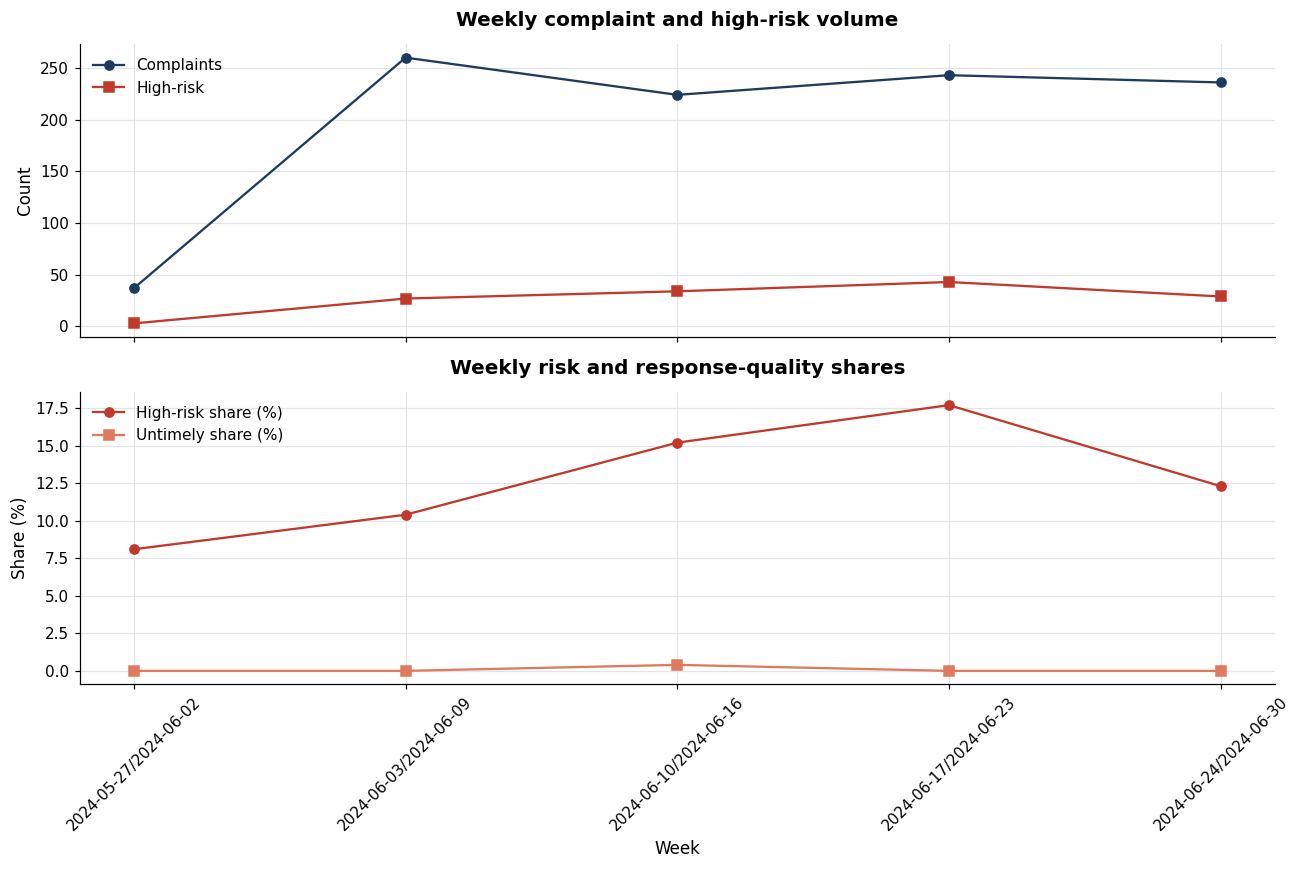

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
axes[0].plot(weekly["week"], weekly["complaints"], marker="o", color=PALETTE["primary"], label="Complaints")
axes[0].plot(weekly["week"], weekly["high_risk"], marker="s", color=PALETTE["warning"], label="High-risk")
axes[0].set_title("Weekly complaint and high-risk volume")
axes[0].set_ylabel("Count")
axes[0].legend()
axes[1].plot(weekly["week"], weekly["high_risk_share_pct"], marker="o", color=PALETTE["warning"], label="High-risk share (%)")
axes[1].plot(weekly["week"], weekly["untimely_share_pct"], marker="s", color=PALETTE["accent"], label="Untimely share (%)")
axes[1].set_title("Weekly risk and response-quality shares")
axes[1].set_xlabel("Week")
axes[1].set_ylabel("Share (%)")
axes[1].legend()
axes[1].tick_params(axis="x", rotation=45)
fig.tight_layout()
save_figure(ctx, fig, "weekly_trend")
plt.show()

## 5. Topic movement this week

In [6]:
topic_weekly = (
    scores.dropna(subset=["topic_id"])
    .assign(topic_id=lambda d: d["topic_id"].astype(int))
    .groupby(["week", "topic_id"], as_index=False).size().rename(columns={"size": "complaints"})
).merge(labels, on="topic_id", how="left")

if observed_weeks < 2:
    topic_move = pd.DataFrame(columns=["topic_id", "topic_label", "latest_complaints", "prev_complaints", "delta_complaints"])
    print("Need at least two weeks to compute topic movement.")
else:
    weeks_sorted = sorted(scores["week"].unique())
    latest_week, prev_week = weeks_sorted[-1], weeks_sorted[-2]
    latest = topic_weekly[topic_weekly["week"] == latest_week][["topic_id", "complaints"]]
    latest = latest.rename(columns={"complaints": "latest_complaints"})
    prev = topic_weekly[topic_weekly["week"] == prev_week][["topic_id", "complaints"]]
    prev = prev.rename(columns={"complaints": "prev_complaints"})
    topic_move = (
        labels.merge(latest, on="topic_id", how="left").merge(prev, on="topic_id", how="left")
    )
    topic_move[["latest_complaints", "prev_complaints"]] = (
        topic_move[["latest_complaints", "prev_complaints"]].fillna(0).astype(int)
    )
    topic_move["delta_complaints"] = topic_move["latest_complaints"] - topic_move["prev_complaints"]
    topic_move = topic_move.sort_values("delta_complaints", ascending=False).reset_index(drop=True)
topic_move.head(10)

,topic_id,topic_label,latest_complaints,prev_complaints,delta_complaints
0,4,"credit, report, credit report, information",103,97,6
1,0,"redacted, redacted redacted, money, account",76,71,5
2,3,"payment, late, payments, creditor",21,18,3
3,6,"letters, party involved, really sure, falsely ...",6,5,1
4,2,"accounts, fcra 605b, significance eliminating,...",11,11,0
5,5,"payments, perplexing discover, perplexing, upd...",4,7,-3
6,1,"consumer, 15, section, states",9,17,-8
7,7,"consumer reports, consent, consumer, reports",6,17,-11


## 6. Escalation checklist & insights

In [7]:
lines: list[str] = []
if observed_weeks < 2:
    lines.append("- Only one week of data is present in the sample; weekly comparison is not possible.")
else:
    current = weekly.iloc[-1]
    previous = weekly.iloc[-2]
    lines.append(
        f"- **Volume**: {int(current['complaints']):,} this week vs. "
        f"{int(previous['complaints']):,} last week "
        f"(delta {int(current['complaints']) - int(previous['complaints']):+,})."
    )
    lines.append(
        f"- **High-risk share**: {current['high_risk_share_pct']:.1f}% "
        f"({current['high_risk_share_pct'] - previous['high_risk_share_pct']:+.1f} pp WoW)."
    )
    if not topic_move.empty:
        rising = topic_move.head(1).iloc[0]
        lines.append(
            f"- **Fastest-rising topic**: Topic {int(rising['topic_id'])} "
            f"({rising['topic_label']}) with delta {int(rising['delta_complaints']):+,} complaints."
        )
lines.extend([
    "",
    "**Escalation triggers** (manual check this week):",
    "1. Complaint volume rises week-over-week by more than 20%.",
    "2. High-risk or untimely share rises more than 2 pp WoW.",
    "3. A single topic gains more than 10 complaints WoW for two weeks in a row.",
])
display(Markdown("\n".join(lines)))

- **Volume**: 236 this week vs. 243 last week (delta -7).
- **High-risk share**: 12.3% (-5.4 pp WoW).
- **Fastest-rising topic**: Topic 4 (credit, report, credit report, information) with delta +6 complaints.

**Escalation triggers** (manual check this week):
1. Complaint volume rises week-over-week by more than 20%.
2. High-risk or untimely share rises more than 2 pp WoW.
3. A single topic gains more than 10 complaints WoW for two weeks in a row.

## Limitations

- The risk score is heuristic, not a legal or regulatory finding. It exists to triage analyst attention.
- CFPB narratives are only published when the consumer consents, so coverage is partial.
- Company-level comparisons mix companies of very different sizes &mdash; always pair them with volume context.
- The sample bundled with this repo is a small subset of the public CFPB dataset and is meant for demonstration, not production decisions.

## Exports

All tables and figures generated above are saved under `reports/notebook/09/`. The environment snapshot is written alongside so a reader can reproduce the run.


In [8]:
save_table(ctx, weekly, "weekly_scorecard")
save_table(ctx, wow, "weekly_wow_deltas")
save_table(ctx, topic_weekly, "topic_weekly_counts")
save_table(ctx, topic_move, "topic_weekly_movement")
write_environment_snapshot(ctx)
sorted(ctx.artefact_dir.iterdir())

[WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/09/environment.json'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/09/topic_weekly_counts.csv'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/09/topic_weekly_movement.csv'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/09/weekly_scorecard.csv'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/09/weekly_trend.png'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/09/weekly_wow_deltas.csv')]